In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("C:\\Users\\Areen\\Desktop\\EVEnergyPrediction\\clean_ev_energy_consumption.csv")

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5002 entries, 0 to 5001
Data columns (total 19 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Vehicle_ID              5002 non-null   int64  
 1   Timestamp               5002 non-null   object 
 2   Speed_kmh               5002 non-null   float64
 3   Acceleration_ms2        5002 non-null   float64
 4   Battery_State_%         5002 non-null   float64
 5   Battery_Voltage_V       5002 non-null   float64
 6   Battery_Temperature_C   5002 non-null   float64
 7   Driving_Mode            5002 non-null   int64  
 8   Road_Type               5002 non-null   int64  
 9   Traffic_Condition       5002 non-null   int64  
 10  Slope_%                 5002 non-null   float64
 11  Weather_Condition       5002 non-null   int64  
 12  Temperature_C           5002 non-null   float64
 13  Humidity_%              5002 non-null   float64
 14  Wind_Speed_ms           5002 non-null   

In [4]:
from sklearn.model_selection import train_test_split

y = df["Energy_Consumption_kWh"]

# 2. استخراج الميزات (X) وحذف الأعمدة غير الضرورية
columns_to_drop = ["Vehicle_ID", "Timestamp", "Energy_Consumption_kWh"]
X = df.drop(columns=[col for col in columns_to_drop if col in df.columns])

# 3. تقسيم البيانات إلى تدريب واختبار (80% تدريب و 20% اختبار)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


print("(X_train):", X_train.shape)
print( "(X_test):", X_test.shape)
print("(y_train):", y_train.shape) 
print("(y_test):", y_test.shape)

(X_train): (4001, 16)
(X_test): (1001, 16)
(y_train): (4001,)
(y_test): (1001,)


In [5]:
categorical_cols = ["Driving_Mode", "Road_Type", "Traffic_Condition", "Weather_Condition"]

numerical_cols = [col for col in X_train.columns if col not in categorical_cols]

# 3. طباعة للتأكد من التقسيم
print(f"عدد الأعمدة الفئوية: {len(categorical_cols)}")
print("الأعمدة الفئوية:", categorical_cols)
print(f"\nعدد الأعمدة الرقمية: {len(numerical_cols)}")
print("الأعمدة الرقمية:", numerical_cols)

عدد الأعمدة الفئوية: 4
الأعمدة الفئوية: ['Driving_Mode', 'Road_Type', 'Traffic_Condition', 'Weather_Condition']

عدد الأعمدة الرقمية: 12
الأعمدة الرقمية: ['Speed_kmh', 'Acceleration_ms2', 'Battery_State_%', 'Battery_Voltage_V', 'Battery_Temperature_C', 'Slope_%', 'Temperature_C', 'Humidity_%', 'Wind_Speed_ms', 'Tire_Pressure_psi', 'Vehicle_Weight_kg', 'Distance_Travelled_km']


In [6]:
# تطبيق get_dummies على الأعمدة الفئوية الأربعة في بياناتك
categorical_cols = ["Driving_Mode", "Road_Type", "Traffic_Condition", "Weather_Condition"]

X_encoded = pd.get_dummies(X, columns=categorical_cols, drop_first=True, dtype=int)

# معاينة شكل الجدول الجديد
print("أبعاد الجدول بعد get_dummies:", X_encoded.shape)
X_encoded.head(2)

أبعاد الجدول بعد get_dummies: (5002, 21)


,Speed_kmh,Acceleration_ms2,Battery_State_%,Battery_Voltage_V,Battery_Temperature_C,Slope_%,Temperature_C,Humidity_%,Wind_Speed_ms,Tire_Pressure_psi,...,Distance_Travelled_km,Driving_Mode_2,Driving_Mode_3,Road_Type_2,Road_Type_3,Traffic_Condition_2,Traffic_Condition_3,Weather_Condition_2,Weather_Condition_3,Weather_Condition_4
0,111.507366,-2.773816,30.415148,378.091525,25.314786,6.879446,0.741770,42.172533,7.829253,31.112020,...,20.757508,1,0,0,0,0,0,0,0,1
1,48.612323,-0.796982,97.385534,392.718377,18.240755,-3.007212,-3.495516,57.018427,4.495572,31.504366,...,0.642918,0,0,1,0,0,0,0,0,1


In [7]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. تقسيم البيانات المرمزة X_encoded
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42
)

# 2. تحديد أسماء الأعمدة الرقمية الـ 12
numerical_cols = [
    "Speed_kmh",
    "Acceleration_ms2",
    "Battery_State_%",
    "Battery_Voltage_V",
    "Battery_Temperature_C",
    "Slope_%",
    "Temperature_C",
    "Humidity_%",
    "Wind_Speed_ms",
    "Tire_Pressure_psi",
    "Vehicle_Weight_kg",
    "Distance_Travelled_km",
]

# 3. إنشاء المعاير وتطبيقه على بيانات التدريب والاختبار
scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[numerical_cols] = scaler.fit_transform(X_train[numerical_cols])
X_test_scaled[numerical_cols] = scaler.transform(X_test[numerical_cols])

# 4. التحقق من شكل الأعمدة النهائي
print("أبعاد ميزات التدريب النهائية:", X_train_scaled.shape)
print("أبعاد ميزات الاختبار النهائية:", X_test_scaled.shape)
X_train_scaled.head(2)

أبعاد ميزات التدريب النهائية: (4001, 21)
أبعاد ميزات الاختبار النهائية: (1001, 21)


,Speed_kmh,Acceleration_ms2,Battery_State_%,Battery_Voltage_V,Battery_Temperature_C,Slope_%,Temperature_C,Humidity_%,Wind_Speed_ms,Tire_Pressure_psi,...,Distance_Travelled_km,Driving_Mode_2,Driving_Mode_3,Road_Type_2,Road_Type_3,Traffic_Condition_2,Traffic_Condition_3,Weather_Condition_2,Weather_Condition_3,Weather_Condition_4
3848,1.451780,-0.424765,0.371706,1.681202,1.019457,1.608666,-0.219688,1.177069,0.313879,-0.834327,...,-1.441821,0,1,0,1,0,0,0,1,0
800,0.688284,-1.334385,-0.092445,1.140003,0.384334,1.100900,0.683144,-0.791019,-0.924688,1.346750,...,-1.038516,1,0,0,1,0,1,0,0,1


Feature engineering


In [8]:
# إنشاء ميزة تمثل القوة التقريبية المبذولة لتسريع المركبة
# القوة = الكتلة (الوزن) × التسارع
X_encoded["Force_Proxy"] = X_encoded["Vehicle_Weight_kg"] * X_encoded["Acceleration_ms2"]

# معاينة الميزة الجديدة
print("تمت إضافة ميزة Force_Proxy بنجاح!")
X_encoded[["Vehicle_Weight_kg", "Acceleration_ms2", "Force_Proxy"]].head(3)

تمت إضافة ميزة Force_Proxy بنجاح!


,Vehicle_Weight_kg,Acceleration_ms2,Force_Proxy
0,1822.967368,-2.773816,-5056.575428
1,2091.831914,-0.796982,-1667.152897
2,1816.702497,0.253800,461.078828


In [9]:
df.shape

(5002, 19)

In [10]:
X_encoded.head(2)

,Speed_kmh,Acceleration_ms2,Battery_State_%,Battery_Voltage_V,Battery_Temperature_C,Slope_%,Temperature_C,Humidity_%,Wind_Speed_ms,Tire_Pressure_psi,...,Driving_Mode_2,Driving_Mode_3,Road_Type_2,Road_Type_3,Traffic_Condition_2,Traffic_Condition_3,Weather_Condition_2,Weather_Condition_3,Weather_Condition_4,Force_Proxy
0,111.507366,-2.773816,30.415148,378.091525,25.314786,6.879446,0.741770,42.172533,7.829253,31.112020,...,1,0,0,0,0,0,0,0,1,-5056.575428
1,48.612323,-0.796982,97.385534,392.718377,18.240755,-3.007212,-3.495516,57.018427,4.495572,31.504366,...,0,0,1,0,0,0,0,0,1,-1667.152897


In [11]:
X_encoded.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5002 entries, 0 to 5001
Data columns (total 22 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Speed_kmh              5002 non-null   float64
 1   Acceleration_ms2       5002 non-null   float64
 2   Battery_State_%        5002 non-null   float64
 3   Battery_Voltage_V      5002 non-null   float64
 4   Battery_Temperature_C  5002 non-null   float64
 5   Slope_%                5002 non-null   float64
 6   Temperature_C          5002 non-null   float64
 7   Humidity_%             5002 non-null   float64
 8   Wind_Speed_ms          5002 non-null   float64
 9   Tire_Pressure_psi      5002 non-null   float64
 10  Vehicle_Weight_kg      5002 non-null   float64
 11  Distance_Travelled_km  5002 non-null   float64
 12  Driving_Mode_2         5002 non-null   int64  
 13  Driving_Mode_3         5002 non-null   int64  
 14  Road_Type_2            5002 non-null   int64  
 15  Road

In [12]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
df_scaled = pd.DataFrame(scaler.fit_transform(X_encoded), columns=X_encoded.columns)
print(X_encoded.max())
# فحص القيمة العظمى للأعمدة الرقمية المعايرة
print(X_train_scaled[numerical_cols].max())

Speed_kmh                 120.000000
Acceleration_ms2            2.998039
Battery_State_%            99.993986
Battery_Voltage_V         400.000000
Battery_Temperature_C      44.985943
Slope_%                     9.998358
Temperature_C              39.998063
Humidity_%                 89.988891
Wind_Speed_ms              14.999095
Tire_Pressure_psi          35.000000
Vehicle_Weight_kg        2499.504564
Distance_Travelled_km      49.993767
Driving_Mode_2              1.000000
Driving_Mode_3              1.000000
Road_Type_2                 1.000000
Road_Type_3                 1.000000
Traffic_Condition_2         1.000000
Traffic_Condition_3         1.000000
Weather_Condition_2         1.000000
Weather_Condition_3         1.000000
Weather_Condition_4         1.000000
Force_Proxy              7444.816832
dtype: float64
Speed_kmh                1.744291
Acceleration_ms2         1.736545
Battery_State_%          1.708851
Battery_Voltage_V        1.691211
Battery_Temperature_C    1.740380
S

### نموذج شجرة القرار (Decision Tree Regressor)

قمنا بتدريب نموذج شجرة قرار لتوقع استهلاك طاقة البطارية مع تحديد أقصى عمق `max_depth=5` للحد من فرط التخصيص (Overfitting).

#### النتائج وتفسير الأداء:
* **Train Score ($R^2$):** 0.84 (84%)
* **Test Score ($R^2$):** 0.80 (80%)
* **الاستنتاج:**
  * تحسنت الدقة بشكل ملحوظ من **59%** (في الانحدار الخطي) إلى **80%**، لأن شجرة القرار قادرة على التقاط العلاقات والتداخلات غير الخطية بين المتغيرات.
  * الفارق بين التدريب والاختبار ضئيل جداً (4%)، ما يثبت أن النموذج متزن ومُعمم بشكل ممتاز ولا يعاني من حفظ البيانات (No Overfitting).

In [13]:
from sklearn.tree import DecisionTreeRegressor

model = DecisionTreeRegressor(max_depth=5, random_state=42)
model.fit(X_train, y_train)

train_score = model.score(X_train, y_train)
test_score = model.score(X_test, y_test)
print(f"Train Score: {train_score:.2f}")
print(f"Test Score: {test_score:.2f}")

Train Score: 0.84
Test Score: 0.80


 **الفجوة بين التدريب والاختبار (Gap = 0.04):** فارق بسيط جداً (4%) يؤكد أن النموذج معمّم بشكل سليم ولا يعاني من حفظ البيانات (Overfitting).

In [14]:
gap=train_score - test_score
print(f"Gap between Train and Test Score: {gap:.2f}")

Gap between Train and Test Score: 0.04


### الانحدار الخطي البسيط (Simple Linear Regression)

تدريب النموذج باستخدام ميزة السرعة فقط (`Speed_kmh`):
* **معادلة النموذج:** $\text{Energy} = 5.42 + 0.05 \times \text{Speed}$
* **المعامل (0.05):** زيادة السرعة بمقدار 1 كم/ساعة ترفع استهلاك البطارية بحوالي 0.05 kWh بسبب مقاومة الهواء والاحتكاك.
* **نقطة التقاطع (5.42):** استهلاك الطاقة الأساسي للأجهزة الكهربائية الداخلية عند توقف السيارة تماماً.

In [15]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train[["Speed_kmh"]], y_train)
print(f"Coefficient: {model.coef_[0]:.2f}")
print(f"Intercept: {model.intercept_:.2f}")

Coefficient: 0.05
Intercept: 5.42


### الانحدار الخطي البسيط: ضغط الإطارات (Tire Pressure)

* **المعادلة:** $\text{Energy} = 10.20 - 0.06 \times \text{Tire\_Pressure\_psi}$
* **المعامل (-0.06):** علاقة عكسية؛ زيادة ضغط الإطارات بمقدار 1 psi تقلل استهلاك الطاقة بحوالي 0.06 kWh نتيجة انخفاض مقاومة دوران العجلات مع الطريق.
* **نقطة التقاطع (10.20):** قيمة تقاطع الخط رياضياً عند انعدام الضغط.

In [16]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train[["Tire_Pressure_psi"]], y_train)
print(f"Coefficient: {model.coef_[0]:.2f}")
print(f"Intercept: {model.intercept_:.2f}")

Coefficient: -0.06
Intercept: 10.20


### الانحدار الخطي المتعدد (Multiple Linear Regression)

* **المعادلة الرياضية:**
  $$\text{Energy} = 6.58 + (0.0504 \times \text{Speed}) - (0.0345 \times \text{Tire Pressure}) - (0.0036 \times \text{Temp})$$

* **التفسير:**
  1. **السرعة (+0.0504):** المتغير الأكثر تأثيراً؛ زيادة السرعة بـ 1 كم/س تزيد الاستهلاك بحوالي 0.05 kWh بسبب مقاومة الرياح.
  2. **ضغط الإطارات (-0.0345):** زيادة الضغط بـ 1 psi تخفض الاستهلاك بمقدار 0.035 kWh لتقليل مقاومة الدوران.
  3. **الحرارة (-0.0036):** أثر طفيف لتحسن كفاءة عمل خلايا البطارية في الطقس المعتدل.
  4. **نقطة التقاطع (6.58):** استهلاك الأنظمة والأجهزة الداخلية الأساسية للسيارة.

In [17]:
features = ["Temperature_C", "Speed_kmh", "Tire_Pressure_psi"]

for feature, coef in zip(features, model.coef_):
    print(f"{feature}: {coef:.4f}")

print(f"(Intercept): {model.intercept_:.2f}")

Temperature_C: -0.0564
(Intercept): 10.20


### تفسير الرسم البياني: العلاقة بين السرعة واستهلاك الطاقة (Speed vs. Energy Consumption)

يوضح الرسم البياني نتائج تطبيق الانحدار الخطي البسيط لدراسة أثر سرعة السيارة على استهلاك طاقة البطارية:

* **النقاط الزرقاء (Actual Data):** تمثل قراءات الرحلات الفعلية، ويظهر من خلالها تشتت طبيعي لاستهلاك الطاقة حول كل سرعة نتيجة عوامل واقعية أخرى (مثل أسلوب القيادة أو ظروف الطريق).
* **الخط الأحمر (Regression Line):** يمثل تنبؤات نموذج الانحدار الخطي، حيث يمر في منتصف مسار البيانات ليعبر عن الاتجاه العام بدقة.
* **الاستنتاج الفيزيائي:**
  1. **علاقة طردية قوية:** نلاحظ ميلاً صاعداً واضحاً للخط؛ فكلما زادت سرعة السيارة من 0 إلى 120 كم/ساعة، ارتفع استهلاك الطاقة من حوالي 5.4 kWh إلى ما يزيد عن 11.4 kWh بسبب تزايد مقاومة الهواء (Aerodynamic Drag).
  2. **الاستهلاك الأساسي (Intercept):** يبدأ الخط عند سرعة صفر بقيمة تقارب 5.42 kWh، وهو ما يمثل الطاقة المستهلكة لتشغيل الأنظمة الإلكترونية والتحكم داخل السيارة عند توقفها.

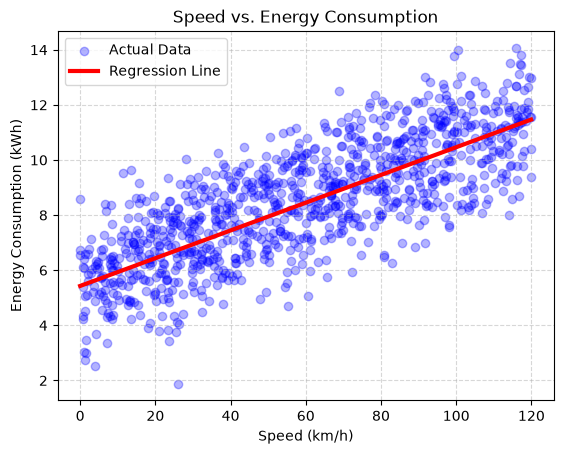

In [18]:
import numpy as np
import matplotlib.pyplot as plt

# 1. رسم نقاط البيانات الفعلية
plt.scatter(X_test["Speed_kmh"], y_test, color="blue", alpha=0.3, label="Actual Data")

# 2. إنشاء قيم سرعة مرتبة تصاعدياً من أصغر سرعة لأكبر سرعة
speed_range = np.linspace(X_test["Speed_kmh"].min(), X_test["Speed_kmh"].max(), 100).reshape(-1, 1)

# حساب التنبؤات لقيم السرعة المرتبة
features = ["Temperature_C", "Speed_kmh", "Tire_Pressure_psi"]

model = LinearRegression()
model.fit(X_train[features], y_train)

plot_df = pd.DataFrame({
    "Temperature_C": X_test["Temperature_C"].mean(),
    "Speed_kmh": speed_range.ravel(),
    "Tire_Pressure_psi": X_test["Tire_Pressure_psi"].mean()
})

y_line_pred = model.predict(plot_df)

# رسم خط الانحدار بشكل مستقيم وسليم
plt.plot(speed_range, y_line_pred, color="red", linewidth=3, label="Regression Line")

# 3. العناوين وتنسيق المحاور
plt.title("Speed vs. Energy Consumption", fontsize=12)
plt.xlabel("Speed (km/h)", fontsize=10)
plt.ylabel("Energy Consumption (kWh)", fontsize=10)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)

plt.show()

### تقييم النموذج: متوسط الخطأ المطلق (MAE)

* **القيمة:** 1.1203 kWh
* **التفسير:** يخطئ النموذج في المتوسط بمقدار 1.12 كيلوواط/ساعة عن الاستهلاك الفعلي لبطارية السيارة لكل رحلة، وهو مقياس مباشر وسهل التفسير لحجم الخطأ النموذجي.

In [19]:
from sklearn.metrics import mean_absolute_error
mea=mean_absolute_error(y_test, model.predict(X_test[["Temperature_C", "Speed_kmh", "Tire_Pressure_psi"]]))
print(f"Mean Absolute Error (MAE): {mea:.4f}")

Mean Absolute Error (MAE): 1.1203


### تقييم النموذج: متوسط مربع الخطأ (MSE)

* **القيمة:** 1.8835 (kWh)²
* **التفسير:** يقيس متوسط مربعات الفروق بين القيم الحقيقية والمتوقعة، ويتميز بأنه يعاقب الأخطاء الكبيرة بشدة، وتُستخدم هذه القيمة بشكل رئيسي لحساب الجذر التربيعي للخطأ (RMSE) لإعادته إلى وحدة القياس الأصلية.

In [20]:
from sklearn.metrics import mean_squared_error
import numpy as np
mse = mean_squared_error(y_test, model.predict(X_test[["Temperature_C", "Speed_kmh", "Tire_Pressure_psi"]]))
print(f"Mean Squared Error (MSE): {mse:.4f}")

Mean Squared Error (MSE): 1.8835


### تقييم النموذج: الجذر التربيعي لمتوسط مربع الخطأ (RMSE)

* **القيمة:** 1.3724 kWh
* **التفسير:** يمثل الانحراف المعياري للأخطاء التقديرية بوحدة الكيلوواط/ساعة؛ ونظراً لقربه من قيمة MAE (1.12 kWh)، فهذا يشير إلى استقرار النموذج وعدم وجود أخطاء شاذة فادحة في تنبؤات استهلاك البطارية.

In [21]:
rmse = np.sqrt(mse)
print(f"Root Mean Squared Error (RMSE): {rmse:.4f} kWh")

Root Mean Squared Error (RMSE): 1.3724 kWh


### تقييم النموذج: معامل التحديد (R² Score)

* **القيمة:** 0.5921 (59.21%)
* **التفسير الإحصائي:** 
  * يفسر النموذج حوالي 59.2% من التباين في استهلاك طاقة بطارية السيارة باستخدام المتغيرات الثلاثة (السرعة، ضغط الإطارات، ودرجة الحرارة).
  * النسبة المتبقية (~40.8%) تعود لمتغيرات وظروف أخرى غير مشمولة في النموذج مثل تشغيل المكيف وطبيعة تضاريس الطريق.

In [22]:
from sklearn.metrics import r2_score
r2 = r2_score(y_test, model.predict(X_test[["Temperature_C", "Speed_kmh", "Tire_Pressure_psi"]]))
print(f"R-squared (R²): {r2:.4f}")

R-squared (R²): 0.5921


(Overfitting Check)

* **Train R²:** 0.6384 (63.84%)
* **Test R²:** 0.5921 (59.21%)
* **الاستنتاج:**
  * الفارق بين التدريب والاختبار ضئيل جداً (~4.6%)، مما يثبت أن النموذج متزن  (No Overfitting)

In [23]:
# 1. التنبؤ على بيانات التدريب
y_train_pred = model.predict(X_train[["Temperature_C", "Speed_kmh", "Tire_Pressure_psi"]])

# 2. حساب R2 لبيانات التدريب
r2_train = r2_score(y_train, y_train_pred)

print(f"Train R²: {r2_train:.4f}")
print(f"Test R²:  {r2:.4f}")

Train R²: 0.6384
Test R²:  0.5921


تفسير نتائج نموذج الانحدار الخطي المتعدد (Multiple Linear Regression)
يوضح النموذج العلاقة بين استهلاك الطاقة وثلاثة متغيرات، وهي درجة الحرارة وسرعة السيارة وضغط الإطارات.
- المعاملات (Coefficients): أظهرت النتائج أن معامل درجة الحرارة يساوي -0.0036، ومعامل السرعة 0.0504، ومعامل ضغط الإطارات -0.0345. تشير هذه القيم إلى اتجاه تأثير كل متغير على استهلاك الطاقة مع تثبيت المتغيرات الأخرى.
- الثابت (Intercept): بلغت قيمته 6.577، ويمثل القيمة المتوقعة لاستهلاك الطاقة عندما تكون قيم المتغيرات المستقلة صفرًا.
- نتيجة التدريب (Train Score): بلغت 0.64، أي أن النموذج يفسر 64% من التباين في بيانات التدريب.
- نتيجة الاختبار (Test Score): بلغت 0.59، أي أن النموذج يفسر 59% من التباين في بيانات الاختبار.
- الفجوة (Gap): بلغت 0.05، مما يشير إلى تقارب أداء النموذج على بيانات التدريب والاختبار.

In [24]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train[["Temperature_C", "Speed_kmh", "Tire_Pressure_psi"]], y_train)

print("Coefficients:", model.coef_)
print("Intercept:", model.intercept_)

Coefficients: [-0.00362415  0.0503502  -0.03447727]
Intercept: 6.577273611124031


In [25]:
train_score = model.score(
    X_train[["Temperature_C", "Speed_kmh", "Tire_Pressure_psi"]], y_train
)
test_score = model.score(
    X_test[["Temperature_C", "Speed_kmh", "Tire_Pressure_psi"]], y_test
)

print(f"Train Score (R2): {train_score:.2f}")
print(f"Test Score (R2): {test_score:.2f}")
print(f"Gap: {train_score - test_score:.2f}")

Train Score (R2): 0.64
Test Score (R2): 0.59
Gap: 0.05


In [26]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

# التنبؤ ببيانات الاختبار
y_pred = model.predict(
    X_test[["Temperature_C", "Speed_kmh", "Tire_Pressure_psi"]]
)

# حساب مقاييس الخطأ
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"MAE: {mae:.2f}")
print(f"RMSE: {rmse:.2f}")

MAE: 1.12
RMSE: 1.37


##Logistic Regression

making prediction and probablities




In [27]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

# 1. تحديد الميزات وتحويل الهدف إلى فئتين (0 و 1)
features = ["Temperature_C", "Speed_kmh", "Tire_Pressure_psi"]
median_val = y_train.median()
y_train_class = (y_train > median_val).astype(int)
y_test_class = (y_test > median_val).astype(int)

# 2. تقييس الميزات (Scaling)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train[features])
X_test_scaled = scaler.transform(X_test[features])

# 3. بناء وتدريب نموذج الانحدار اللوجستي
logistic_model = LogisticRegression(max_iter=1000)
logistic_model.fit(X_train_scaled, y_train_class)

# 4. استخراج التنبؤات والاحتمالات
predictions = logistic_model.predict(X_test_scaled)
probability = logistic_model.predict_proba(X_test_scaled)

print("Predictions (First 5):")
print(predictions[:5])

print("\nProbabilities (First 5):")
print(probability[:5])

Predictions (First 5):
[0 0 0 0 1]

Probabilities (First 5):
[[0.80037657 0.19962343]
 [0.83587524 0.16412476]
 [0.93916847 0.06083153]
 [0.8855713  0.1144287 ]
 [0.06975185 0.93024815]]


In [28]:
import pandas as pd

pd.Series(predictions).value_counts()

0    508
1    493
Name: count, dtype: int64

In [29]:
print(f"عدد صفوف التدريب (Train): {len(X_train)}")
print(f"عدد صفوف الاختبار (Test):  {len(X_test)}")
print(f"إجمالي الصفوف الكلي:        {len(X_train) + len(X_test)}")

عدد صفوف التدريب (Train): 4001
عدد صفوف الاختبار (Test):  1001
إجمالي الصفوف الكلي:        5002


Fitting KNN Classifier With Cross Validation

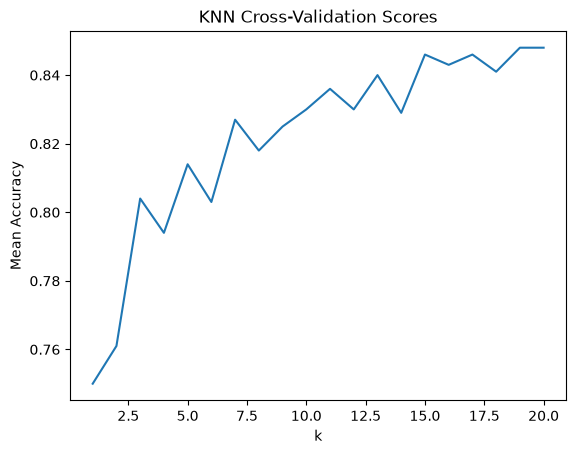

In [30]:
from sklearn.model_selection import cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.datasets import make_classification
import numpy as np
import matplotlib.pyplot as plt
X_train,y_train=make_classification(n_samples=1000, n_features=20, n_classes=2, random_state=42)
k_values = range(1, 21)
mean_accuracies = []
for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(knn, X_train, y_train, cv=5)
    mean_accuracies.append(scores.mean())

plt.plot(k_values, mean_accuracies)
plt.xlabel('k')
plt.ylabel('Mean Accuracy')
plt.title('KNN Cross-Validation Scores')
plt.show()

In [31]:
print("X_train_scaled shape:", X_train_scaled.shape)
print("y_train shape:", y_train.shape)

X_train_scaled shape: (4001, 3)
y_train shape: (1000,)


In [32]:
print("عدد القيم الفريدة في y:", y.nunique())
print("أول 10 قيم من y:\n", y.head(10))
print("نوع بيانات y:", y.dtype)

عدد القيم الفريدة في y: 5002
أول 10 قيم من y:
 0    12.054317
1     4.488701
2    11.701377
3     7.389266
4     6.761205
5     4.319061
6     9.285725
7    10.154375
8     8.734982
9     9.139608
Name: Energy_Consumption_kWh, dtype: float64
نوع بيانات y: float64


In [33]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np
from sklearn.preprocessing import StandardScaler

# 1. تدريب نموذج الانحدار بالقيمة المثالية (K=10)
final_knn_reg = KNeighborsRegressor(n_neighbors=10)
features = ["Temperature_C", "Speed_kmh", "Tire_Pressure_psi"]
X_knn_train, X_knn_test, y_train, y_test = train_test_split(
    X[features], y, test_size=0.2, random_state=42
)

knn_scaler = StandardScaler()
X_train_scaled = knn_scaler.fit_transform(X_knn_train)
X_test_scaled = knn_scaler.transform(X_knn_test)

final_knn_reg.fit(X_train_scaled, y_train)

# 2. التنبؤ على بيانات الاختبار
y_pred = final_knn_reg.predict(X_test_scaled)

# 3. تقييم الأداء الحقيقي للنموذج
print(f"R² Score: {r2_score(y_test, y_pred):.4f}")
print(f"MAE: {mean_absolute_error(y_test, y_pred):.4f} kWh")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.4f} kWh")

R² Score: 0.5507
MAE: 1.1633 kWh
RMSE: 1.4404 kWh


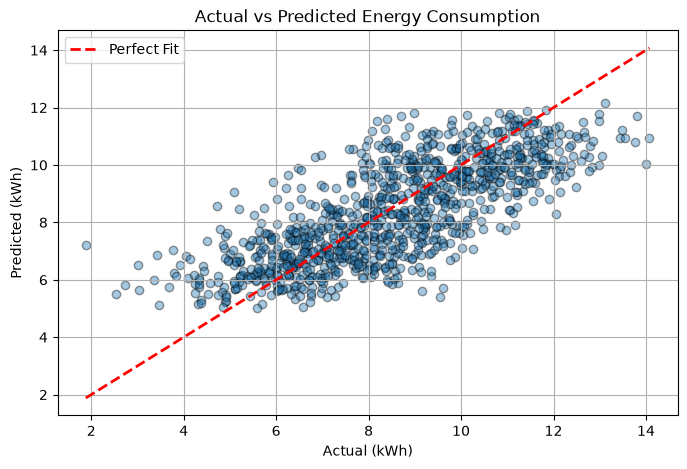

In [34]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred, alpha=0.4, color='#1f77b4', edgecolors='k')
# رسم خط التطابق التام (الخط المثالي للتنبؤ)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Perfect Fit')

plt.title('Actual vs Predicted Energy Consumption')
plt.xlabel('Actual (kWh)')
plt.ylabel('Predicted (kWh)')
plt.legend()
plt.grid(True)
plt.show()

Optimal K for your project: 25
Best CV R2 Score: 0.6252


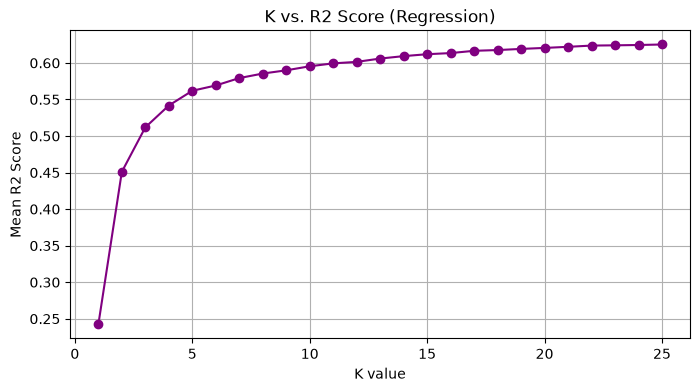

In [35]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import cross_val_score

# نطاق قيم K للتجربة
k_values = range(1, 26)
r2_scores = []

for k in k_values:
    model = KNeighborsRegressor(n_neighbors=k)
    # استخدام scoring='r2' لتقييم الانحدار
    scores = cross_val_score(model, X_train_scaled, y_train, cv=5, scoring='r2')
    r2_scores.append(np.mean(scores))

# معرفة أفضل K
best_k = list(k_values)[np.argmax(r2_scores)]
print(f"Optimal K for your project: {best_k}")
print(f"Best CV R2 Score: {max(r2_scores):.4f}")

# رسم المنحنى لبيانات مشروعك
plt.figure(figsize=(8, 4))
plt.plot(list(k_values), r2_scores, marker='o', color='purple')
plt.xlabel('K value')
plt.ylabel('Mean R2 Score')
plt.title('K vs. R2 Score (Regression)')
plt.grid(True)
plt.show()

In [36]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. التقسيم مع الانتباه للترتيب بدقة
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 2. التأكد من الأبعاد قبل التحويل
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

# 3. توحيد المقاييس
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

X_train shape: (4001, 16)
y_train shape: (4001,)


In [37]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
accuracy = accuracy_score(y_test_class, predictions)
print(f"Accuracy: {accuracy:.4f}")

Accuracy: 0.7922


##Confusion Matrix

Confusion Matrix:
 [[394  94]
 [114 399]]


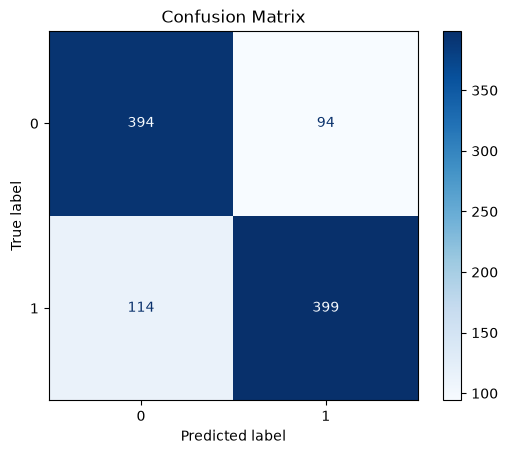

In [38]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# حساب مصفوفة الارتباك
cm = confusion_matrix(y_test_class, predictions)
print("Confusion Matrix:\n", cm)

# رسم المصفوفة بصرياً
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap='Blues')
plt.title("Confusion Matrix")
plt.show()

##Precision and Recall

In [39]:
from sklearn.metrics import precision_score, recall_score, f1_score
precision = precision_score(y_test_class, predictions)
recall = recall_score(y_test_class, predictions)
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")

Precision: 0.8093
Recall: 0.7778


##F1 Score

In [40]:
from sklearn.metrics import f1_score
f1 = f1_score(y_test_class, predictions)
print(f"F1-Score: {f1:.4f}")

F1-Score: 0.7932
